   Berat  Intensitas_Warna Tekstur   Buah
0    150                 7   Halus   Apel
1    170                 8   Halus  Jeruk
2    140                 5   Kasar  Jeruk
3    130                 4   Halus   Apel
4    160                 6   Kasar   Apel
5    180                 8   Kasar  Jeruk
6    120                 3   Kasar   Apel
7    155                 6   Halus  Jeruk
Hasil Prediksi (0=Apel, 1=Jeruk): 0
Probabilitas: [0.8 0.2]
Prediksi Buah: Apel
Akurasi training: 0.75


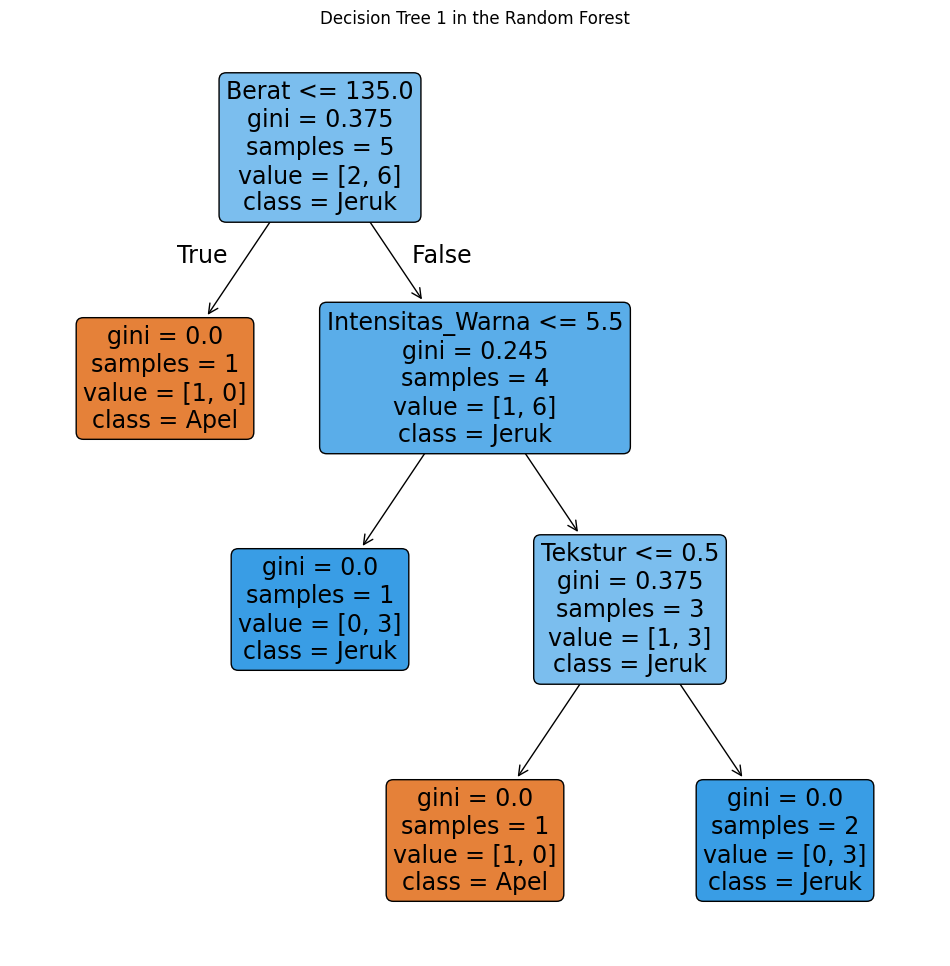

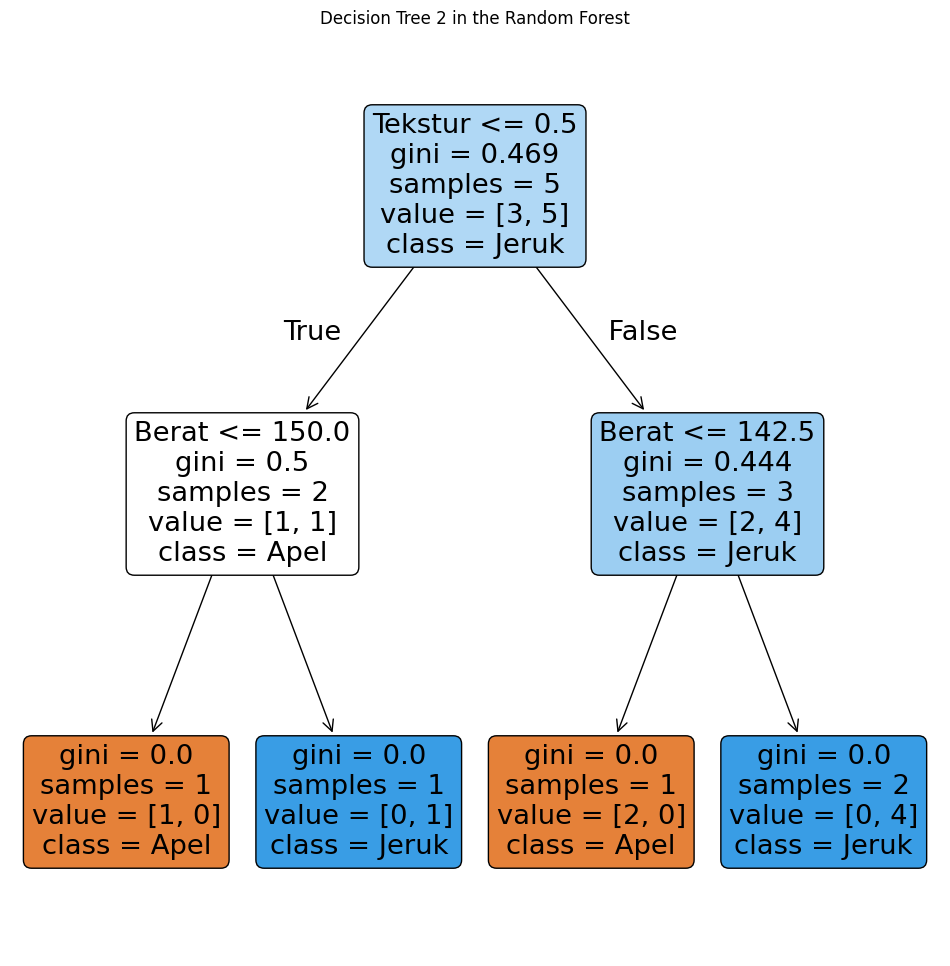

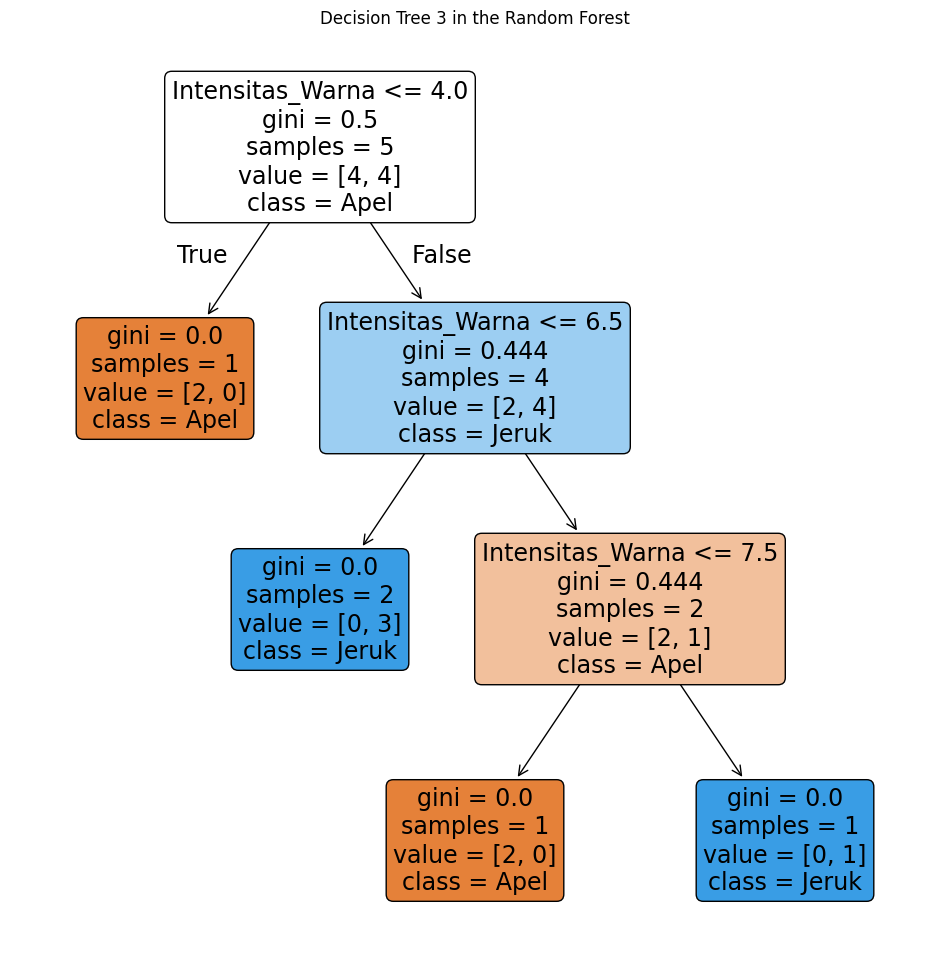

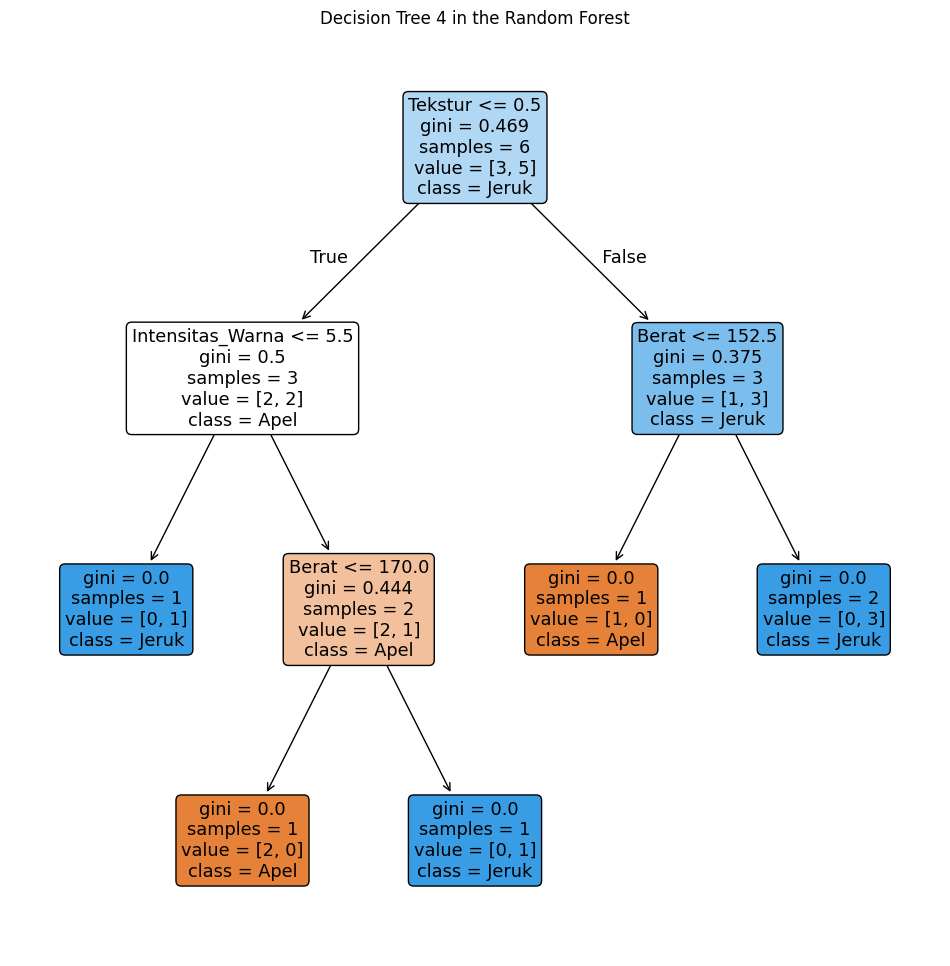

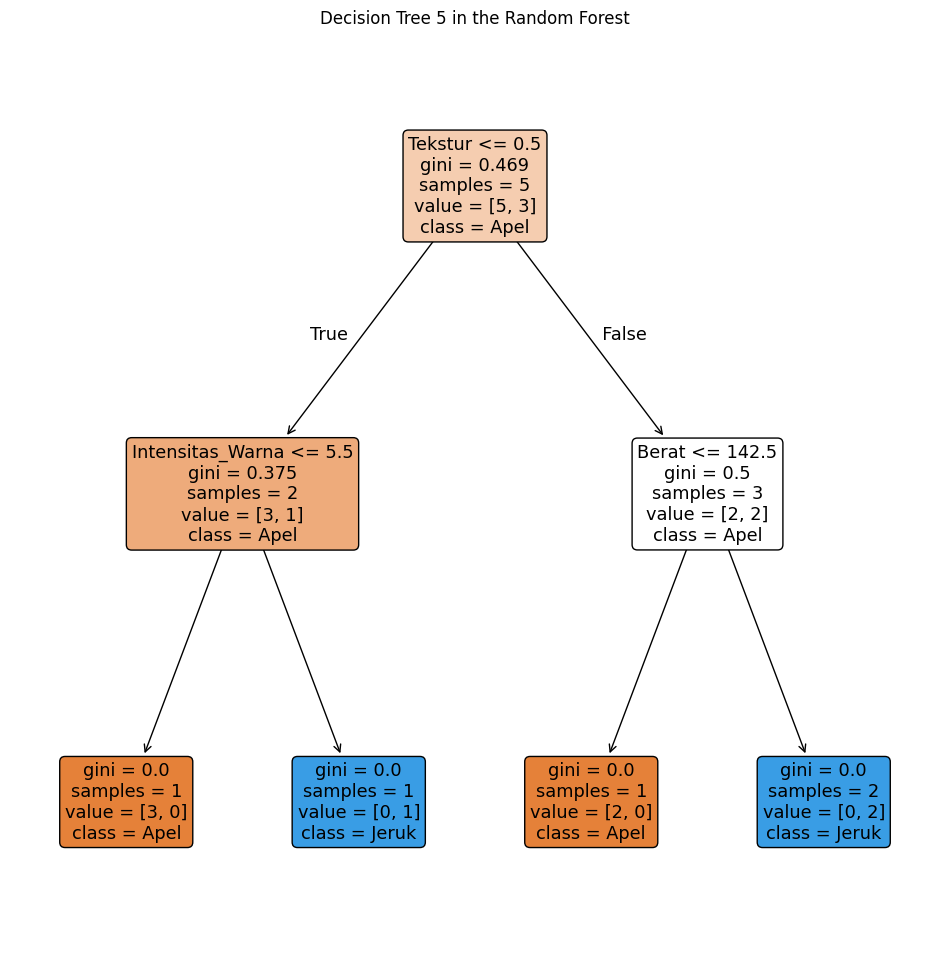

n_estimators=5, accuracy=0.75
n_estimators=10, accuracy=1.0
n_estimators=50, accuracy=1.0


In [1]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

#tentukan dataset
data = {
    'Berat': [150, 170, 140, 130, 160, 180, 120, 155],
    'Intensitas_Warna': [7, 8, 5, 4, 6, 8, 3, 6],
    'Tekstur': ['Halus', 'Halus', 'Kasar', 'Halus', 'Kasar', 'Kasar', 'Kasar', 'Halus'],
    'Buah':['Apel', 'Jeruk', 'Jeruk', 'Apel', 'Apel', 'Jeruk', 'Apel', 'Jeruk']
}

# Buat Data Frame

df = pd.DataFrame(data)

print(df)

# Encode target variabel (Apel = 0 , Orange = 1)

df['Buah'] = df['Buah'].apply(lambda x: 1 if x == 'Jeruk' else 0)

# Encode target variabel (Rough = 0 , Smooth = 1)

df['Tekstur'] = df['Tekstur'].apply(lambda x:1 if x == 'Halus' else 0)

#Features and Target
X = df[['Berat', 'Intensitas_Warna', 'Tekstur']]
y = df['Buah']

#inisialisasi dan latihan model

forest = RandomForestClassifier(n_estimators=5, max_depth=3, random_state=42) 
forest.fit(X,y)

# Data baru (HARUS sesuai format training)
data_baru = pd.DataFrame([[120, 8, 1]], 
columns=['Berat', 'Intensitas_Warna', 'Tekstur'])

# Prediksi
hasil = forest.predict(data_baru)

# Probabilitas (opsional, tapi bagus untuk pembelajaran)
prob = forest.predict_proba(data_baru)

# Output
print("Hasil Prediksi (0=Apel, 1=Jeruk):", hasil[0])
print("Probabilitas:", prob[0])

# Ubah ke label biar lebih jelas
label = "Jeruk" if hasil[0] == 1 else "Apel"
print("Prediksi Buah:", label)
print("Akurasi training:", forest.score(X, y))


#plotting
label = "Jeruk" if hasil[0] == 1 else "Apel"

for i, tree in enumerate(forest.estimators_): 
    plt.figure(figsize=(12,12)) 
    plot_tree(tree, feature_names=['Berat', 'Intensitas_Warna', 'Tekstur'], 
              class_names=['Apel', 'Jeruk'], filled=True, rounded=True) 
    plt.title(f"Decision Tree {i+1} in the Random Forest") 
    plt.show()

#hypertunning
forest = RandomForestClassifier(n_estimators=5, max_depth=3, random_state=42) 

#manual tunning
for n in [5, 10, 50]:
    model = RandomForestClassifier(n_estimators=n, random_state=42)
    model.fit(X, y)
    acc = model.score(X, y)
    print(f"n_estimators={n}, accuracy={acc}")